## Benchmark SANOS

Fitting SANOS with various smoothnesses across 10Y of SPX data.

In [1]:


%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries
%aimport quantdata.sanos.arbfree
%aimport quantdata.sanos.sanos_tools
%aimport quantdata.sanos.sanos



## Limit to 1000 Options

00: Processed 2640 dates for SPX.                                                                
dict_keys(['market_pcnt', 'market_median', 'market_mean', 'target_pcnt', 'target_median', 'target_mean', 'run_time', 'num_options'])


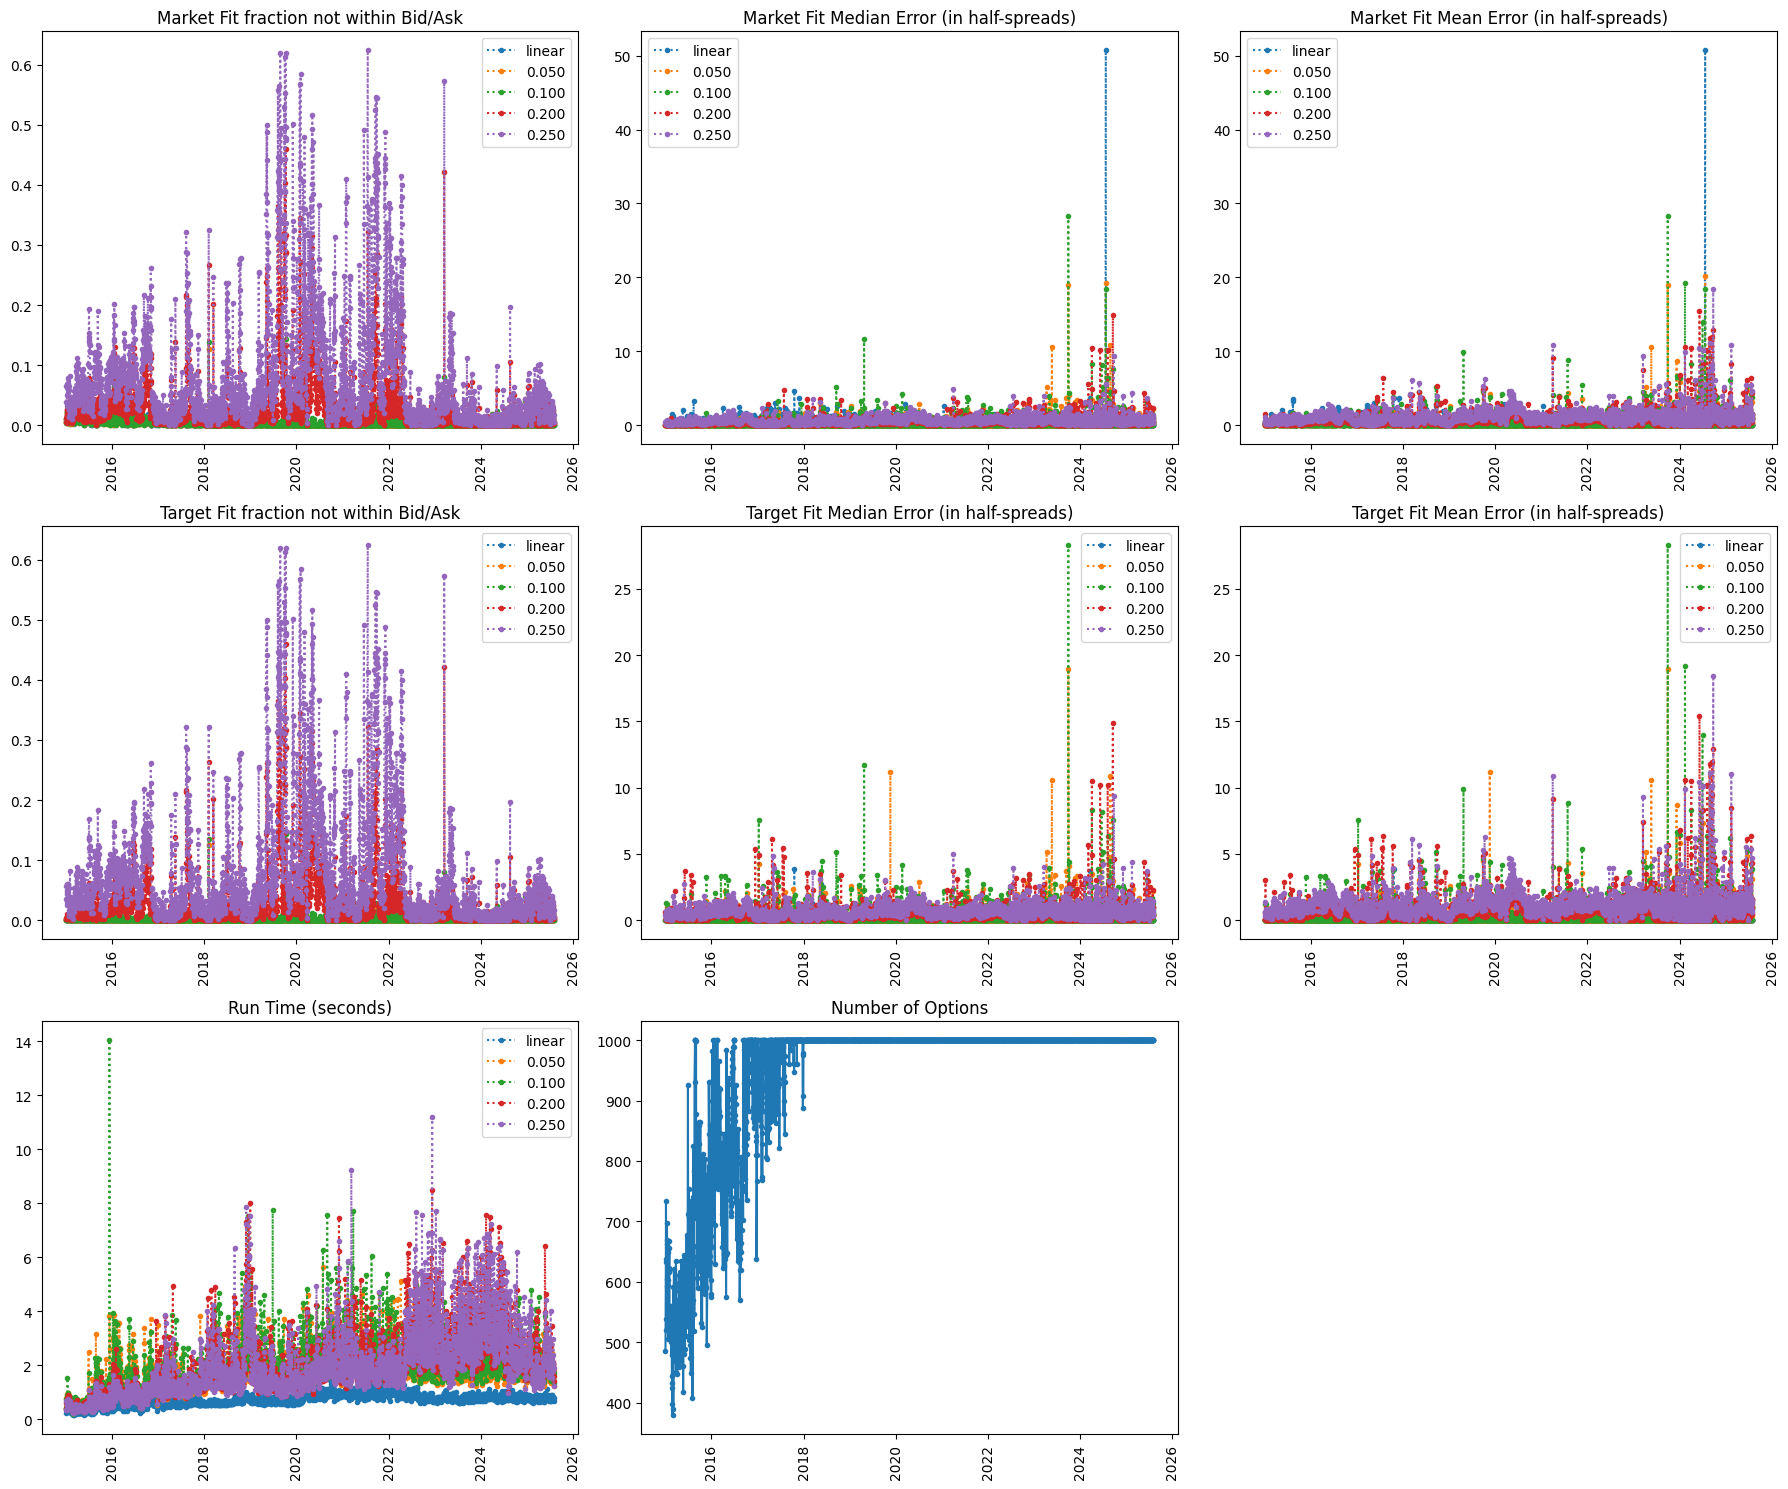

## Unlimited Options

00: Processing SPX 2015-01-02 1/2640... run times 0.2s, 0.4s, 0.4s, 0.4s and 0.4s for 485 options

In [ ]:
from cdxcore.jcpool import JCPool
from cdxcore.pretty import PrettyObject
from cdxcore.subdir import SubDir
from cdxcore.util import fmt_date, fmt_dict, fmt_list   
from quantdata.widb.options_filter import filter_options_day, RawDayFilter, ExpiryFilter, OptionsFilter
import numpy as np
from cdxcore.dynaplot import figure, colors_tableau
from quantdata.pool import PoolConfig 
from cdxcore.verbose import Context
from datetime import date
from quantdata.widb.timeseries import build_time_series, TimeSeriesDefinition, ExpiryFilter, RawDayFilter, OptionsFilter, DateRange, PoolConfig, table_of_time_series, MkArbFree
from quantdata.biz_calendar import next_business_day
from cdxcore.util import fmt_date, fmt_dict, fmt_list
from cdxcore.verbose import Context
from IPython.display import display, Markdown
import warnings

SMOOTHNESSES = [None, 0.05, 0.1, 0.2, 0.25]

_cache = SubDir("!/benchmark_sanos")

@_cache(fmt=SubDir.PICKLE).cache(
        "0.2", dependencies=[filter_options_day, MkArbFree],
        uid = lambda ticker, d, max_options, quiet : f"sanos/{ticker}/{d}{'' if max_options is None else f'max{max_options}'}")
def _process( ticker, d, max_options : int|None = None, quiet : bool = False ):
    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    options_filter = OptionsFilter(max_num_options=max_options if not max_options is None else 1000)
    verbose = Context.quiet if quiet else Context.all

    ddata = filter_options_day( ticker, d, raw_day_filter=raw_day_filter, mk_arb_free=MkArbFree(smoothness=None), expiry_filter=expiry_filter, options_filter=options_filter, raise_if_bad_day=False, verbose=Context.quiet )
    if ddata is None or ddata.empty:
        return None

    # extract market data
    strikes  = ddata['pure_strike'].to_numpy()
    asks     = ddata['pure_ask_price'].to_numpy()
    bids     = ddata['pure_bid_price'].to_numpy()
    expiries = ddata['tte_y'].to_numpy()

    market = PrettyObject()
    market.strikes = []
    market.asks = []
    market.bids = []
    market.expiries = []

    utty = np.unique(expiries)
    for u in utty:
        mask = expiries == u
        if np.sum(mask) == 0:
            continue
        market.expiries.append(u)
        strikes_t = strikes[mask]
        ixs       = np.argsort(strikes_t)
        strikes_t = strikes_t[ixs]
        market.strikes.append(strikes_t)
        market.asks.append(asks[mask][ixs])  
        market.bids.append(bids[mask][ixs])
    market.expiries = np.array(market.expiries)

    # fit
    o = PrettyObject(date=d, ticker=ticker)  
    o.market_pcnt = np.zeros((len(SMOOTHNESSES),))
    o.market_median = np.zeros((len(SMOOTHNESSES),))
    o.market_mean = np.zeros((len(SMOOTHNESSES),))
    o.target_pcnt = np.zeros((len(SMOOTHNESSES),))
    o.target_median = np.zeros((len(SMOOTHNESSES),))
    o.target_mean = np.zeros((len(SMOOTHNESSES),))
    o.run_time = np.zeros((len(SMOOTHNESSES),))

    for ism, smoothness in enumerate(SMOOTHNESSES):
        tme           = verbose.timer()
        try:
            r_sanos       = MkArbFree(smoothness=smoothness)( strikes=market.strikes, expiries=market.expiries, bids=market.bids, asks=market.asks, message_context=lambda : f"{ticker} {d}", verbose=Context.quiet )
        except Exception as e:
            warnings.warn(f"Failed to fit SANOS to {ticker} {d} with smoothness {smoothness}: {e}")
            return None

        market_error  = r_sanos.compute_market_fit( **market, and_vols = False )
        focus_error   = r_sanos.compute_market_fit( expiries=r_sanos.expiries,
                                                    strikes=[ market.strikes[t] for t in r_sanos.input_index], 
                                                    bids=[ market.bids[t] for t in r_sanos.input_index],
                                                    asks=[ market.asks[t] for t in r_sanos.input_index],
                                                    masks=r_sanos.masks, and_vols=False )

        verbose.write(lambda : f"Fitted {'linear' if r_sanos.smoothness is None else f'{r_sanos.smoothness:.2f}-smooth'} SANOS to {ticker} {d}. This took {tme}.")
        verbose.report(1,lambda : f"Market fit: {100.-market_error.pcnt_fit*100:.1f}% were fitted within bid/ask. The mean and median error for those options not fitted were {market_error.mean_err:.2f} and {market_error.median_err:.2f}, respectively.")
        verbose.report(1,lambda : f"Target fit: {100.-focus_error.pcnt_fit*100:.1f}% of options actually calibrated to were fitted within bid/ask. The mean and median error for those options not fitted were {focus_error.mean_err:.2f} and {focus_error.median_err:.2f}, respectively.")

        o.market_pcnt[ism] = market_error.pcnt_fit
        o.market_median[ism] = market_error.median_err
        o.market_mean[ism] = market_error.mean_err
        o.target_pcnt[ism] = focus_error.pcnt_fit  
        o.target_median[ism] = focus_error.median_err
        o.target_mean[ism] = focus_error.mean_err
        o.run_time[ism] = tme.seconds

    o.num_options = len(strikes)
    return o

def benchmark( ticker, date_range : DateRange, interval : int = 40, max_options : int|None = None, pool_config : PoolConfig = PoolConfig(), verbose: Context = Context.all ):

    pool  = JCPool(pool_config.num_workers, pool_config.threading)
    dates = date_range.get_business_days()
    dates = dates[::interval]

    quiet   = pool_config.num_workers > 1 or not pool_config.threading
    results = { d: None for d in dates }
    cnt     =   0
    tme     = verbose.timer()
    for d, r in pool.parallel( { d: pool.delayed(_process)( ticker, d, max_options=max_options, quiet=quiet ) for d in dates } ):
        cnt += 1
        if r is None:
            if tme.interval_test(1.):
                verbose.write(lambda : f"\rSkipping {ticker} {d} {cnt}/{len(dates)} since it had no data...")
        else:
            if tme.interval_test(1.):
                verbose.write(lambda : f"\rProcessing {ticker} {d} {cnt}/{len(dates)}... run times {fmt_list(f'{rt:.1f}s' for rt in r.run_time)} for {r.num_options} options", end='')
            r.pop("date")
            r.pop("ticker")
            results[d] = r

    verbose.write(lambda : f"\rProcessed {len(dates)} dates for {ticker}.")

    results = { d: r for d, r in results.items() if not r is None }
    dates   = list(results)
    r1      = results[dates[0]]
    print(r1.keys())

    tables  = PrettyObject()
    for k, v in r1.items():
        tables[k] = np.stack( list( r[k] for r in results.values() ), axis=0 )
        assert len(dates) == tables[k].shape[0], f"Expected number of results to match number of dates, but got {len(dates)} results and {len(dates)} dates."

    # visualize
    # ---------

    labels = {
        "market_pcnt": "Market Fit fraction not within Bid/Ask",
        "market_median": "Market Fit Median Error (in half-spreads)",
        "market_mean": "Market Fit Mean Error (in half-spreads)",
        "target_pcnt": "Target Fit fraction not within Bid/Ask",
        "target_median": "Target Fit Median Error (in half-spreads)",
        "target_mean": "Target Fit Mean Error (in half-spreads)",
        "run_time": "Run Time (seconds)",
        "num_options": "Number of Options"
    }

    with figure(row_size=5, col_size=6, columns=3) as fig:

        for k, v in tables.items():
            ax = fig.add_subplot( labels[k] )
            if len(v.shape) == 2:
                for ism, smoothness in enumerate(SMOOTHNESSES):
                    ax.plot( dates, v[:, ism], ".:", label=f"{smoothness:.3f}" if not smoothness is None else "linear" )
                ax.legend()
            else:
                ax.plot( dates, v, ".-" )

            ax.tick_params(axis="x", labelrotation=90)


ticker      = "SPX"
date_range  = DateRange(start=date(2015, 1, 1), end=date(2025, 8, 1))
pool_config = PoolConfig(num_workers=4, threading=False)

display(Markdown("## Limit to 1000 Options"))

benchmark(ticker, date_range, interval=1, max_options=1000, pool_config=pool_config)

display(Markdown("## Unlimited Options"))

benchmark(ticker, date_range, interval=1, max_options=100000, pool_config=pool_config)
